In [24]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/AML_MSIS/DataSets/student-mat.csv", sep=';')

print("Dimensions:", df.shape)

print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dimensions: (395, 33)

Data Types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
s

In [22]:
import numpy as np

columns = ['studytime', 'absences', 'G3']

for col in columns:
    print(f"\n{col}")
    print("Mean:", round(np.mean(df[col]),2))
    print("Median:", round(np.median(df[col]),2))
    print("Standard Deviation:", round(np.std(df[col]),2))

Q1 = np.percentile(df['absences'], 25)
Q3 = np.percentile(df['absences'], 75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['absences'] < lower) | (df['absences'] > upper)]

print("\nNumber of Outliers:", len(outliers))
print(outliers[['absences']])


studytime
Mean: 2.04
Median: 2.0
Standard Deviation: 0.84

absences
Mean: 5.71
Median: 4.0
Standard Deviation: 7.99

G3
Mean: 10.42
Median: 11.0
Standard Deviation: 4.58

Number of Outliers: 15
     absences
40         25
74         54
103        26
183        56
198        24
205        28
216        22
260        21
276        75
277        22
280        30
307        38
313        22
315        40
320        23


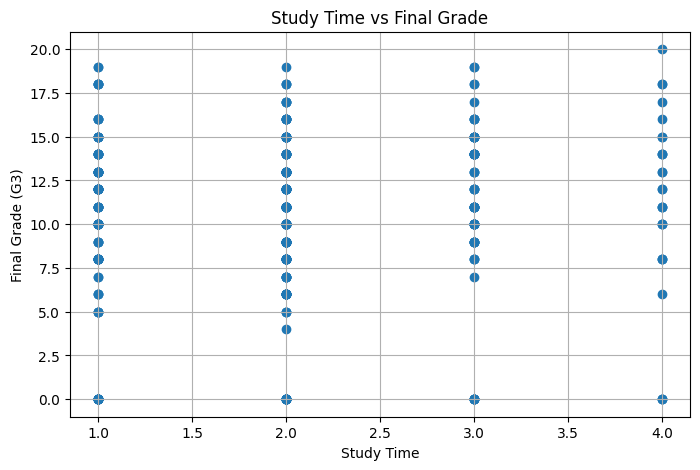

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(df['studytime'], df['G3'])

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time")
plt.ylabel("Final Grade (G3)")

plt.grid(True)

plt.show()


In [23]:
def analyze_column(data, column):

    print("\n-----------------------------")
    print("Column:", column)

    print(round(data[column].describe(),2))

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[(data[column] < lower) | (data[column] > upper)]

    print("Outlier Count:", len(outliers))

# Demonstration
analyze_column(df, "absences")
analyze_column(df, "studytime")


-----------------------------
Column: absences
count    395.00
mean       5.71
std        8.00
min        0.00
25%        0.00
50%        4.00
75%        8.00
max       75.00
Name: absences, dtype: float64
Outlier Count: 15

-----------------------------
Column: studytime
count    395.00
mean       2.04
std        0.84
min        1.00
25%        1.00
50%        2.00
75%        2.00
max        4.00
Name: studytime, dtype: float64
Outlier Count: 27
